# Student Dropout Prediction - Education Analytics
#### Objective: 
The main goal of this project is to construct a robust end-to-end data pipeline to predict student dropout risk. By identifying vulnerable students early using demographic, socioeconomic, and academic indicators, academic institutions can execute strategic interventions. The outcomes are exported into structured datasets optimized for downstream interactive dashboards in Power BI.

## 1. Libraries & Data Collection

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,RandomizedSearchCV, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
from xgboost import XGBClassifier 
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    matthews_corrcoef, log_loss, brier_score_loss, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

import time
from scipy import stats
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

df = pd.read_csv('student_dropout_raw_dataset - Original.csv')
print("--- Dataset Initial Look ---")
print(df.info())

--- Dataset Initial Look ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             10000 non-null  int64  
 1   Age                    10000 non-null  float64
 2   Gender                 10000 non-null  object 
 3   Family_Income          9500 non-null   float64
 4   Internet_Access        10000 non-null  object 
 5   Study_Hours_per_Day    9500 non-null   float64
 6   Attendance_Rate        10000 non-null  float64
 7   Assignment_Delay_Days  10000 non-null  int64  
 8   Travel_Time_Minutes    10000 non-null  float64
 9   Part_Time_Job          10000 non-null  object 
 10  Scholarship            10000 non-null  object 
 11  Stress_Index           9500 non-null   float64
 12  GPA                    10000 non-null  float64
 13  Semester_GPA           10000 non-null  float64
 14  CGPA                   100

## 2. Data Cleaning & Preprocessing

In [2]:
numeric_features = ['Age', 'Family_Income', 'Study_Hours_per_Day', 'Attendance_Rate', 
                    'Assignment_Delay_Days', 'Travel_Time_Minutes', 'Stress_Index', 'GPA', 'Semester_GPA', 'CGPA']
categorical_features = ['Gender', 'Internet_Access', 'Part_Time_Job', 'Scholarship', 'Semester', 'Department', 'Parental_Education']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

## 3. EDA - Exploratory Data Analysis

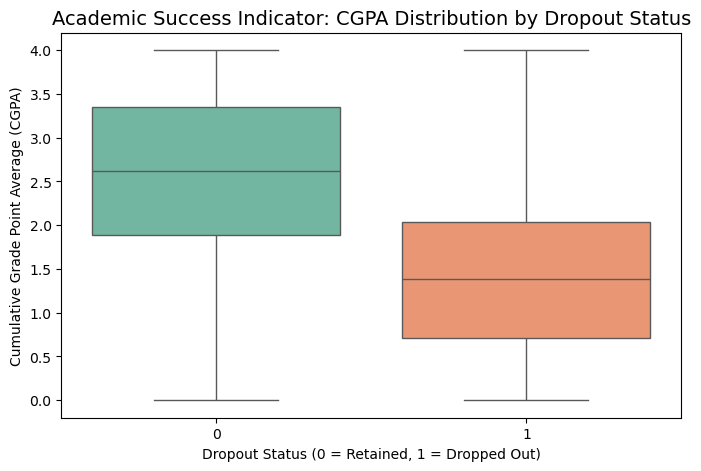

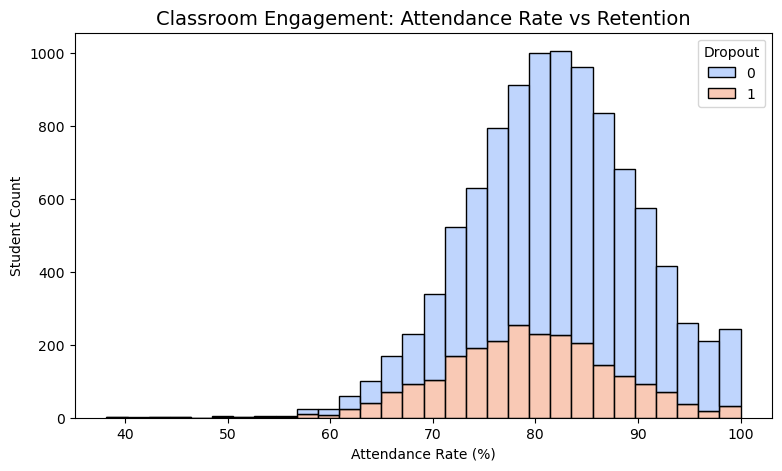

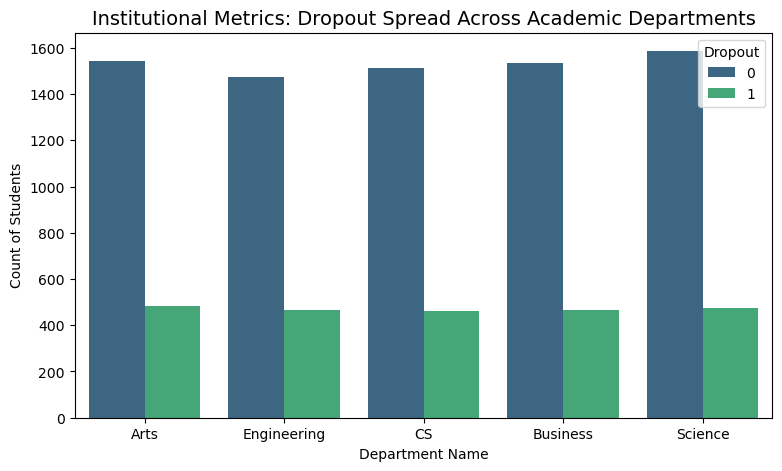

In [3]:
# Visualization 1: Academic Performance Impact (CGPA vs Dropout)
plt.figure(figsize=(8, 5))
sns.boxplot(x='Dropout', y='CGPA', data=df, palette='Set2', hue='Dropout', legend=False)
plt.title('Academic Success Indicator: CGPA Distribution by Dropout Status', fontsize=14)
plt.xlabel('Dropout Status (0 = Retained, 1 = Dropped Out)')
plt.ylabel('Cumulative Grade Point Average (CGPA)')
plt.show()

#Visualization 2: Behavioral Patterns (Attendance Rate)
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Attendance_Rate', hue='Dropout', multiple='stack', bins=30, palette='coolwarm')
plt.title('Classroom Engagement: Attendance Rate vs Retention', fontsize=14)
plt.xlabel('Attendance Rate (%)')
plt.ylabel('Student Count')
plt.show()

# # Visualization 3: Department Breakdown
plt.figure(figsize=(9, 5))
sns.countplot(x='Department', hue='Dropout', data=df, palette='viridis')
plt.title('Institutional Metrics: Dropout Spread Across Academic Departments', fontsize=14)
plt.xlabel('Department Name')
plt.ylabel('Count of Students')
plt.show()

## 4. Model Building

In [7]:
X = df[numeric_features + categorical_features]
y = df['Dropout']

# Fixed stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Calculate class imbalance ratio specifically for XGBoost's scale_pos_weight
scale_pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Calculated scale_pos_weight for XGBoost: {scale_pos_weight_val:.2f}\n")

# =====================================================================
# 2. REUSABLE EVALUATION FUNCTION
# =====================================================================
results_list = []
pred_probas = {}
pred_labels = {}
cv_scores_dict = {}

def evaluate_model(name, classifier_obj):
    # Construct isolated full pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', classifier_obj)
    ])
    
    # Measure Training Time
    t_start_train = time.time()
    pipeline.fit(X_train, y_train)
    fit_time = time.time() - t_start_train
    
    # Measure Prediction Time
    t_start_pred = time.time()
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]
    pred_time = time.time() - t_start_pred
    
    # Cache predictions for plotting
    pred_probas[name] = y_proba
    pred_labels[name] = y_pred
    
    # Overfitting Gap Analysis (Train vs Test)
    y_train_pred = pipeline.predict(X_train)
    y_train_proba = pipeline.predict_proba(X_train)[:, 1]
    train_acc = accuracy_score(y_train, y_train_pred)
    train_auc = roc_auc_score(y_train, y_train_proba)
    
    # Test Metrics
    test_acc = accuracy_score(y_test, y_pred)
    test_prec = precision_score(y_test, y_pred, pos_label=1)
    test_rec = recall_score(y_test, y_pred, pos_label=1)
    test_f1 = f1_score(y_test, y_pred, pos_label=1)
    test_macro_f1 = f1_score(y_test, y_pred, average='macro')
    test_roc_auc = roc_auc_score(y_test, y_proba)
    test_pr_auc = average_precision_score(y_test, y_proba)
    test_bal_acc = balanced_accuracy_score(y_test, y_pred)
    test_mcc = matthews_corrcoef(y_test, y_pred)
    test_log_loss = log_loss(y_test, y_proba)
    test_brier = brier_score_loss(y_test, y_proba)
    
    # 5-Fold Stratified Cross-Validation
    scoring = {'roc_auc': 'roc_auc', 'f1': 'f1', 'recall': 'recall'}
    cv_res = cross_validate(pipeline, X_train, y_train, cv=cv_strategy, scoring=scoring)
    cv_scores_dict[name] = cv_res
    
    metrics = {
        'Model': name,
        'Test Acc': test_acc,
        'Test Precision': test_prec,
        'Test Recall': test_rec,
        'Test F1 (Dropout)': test_f1,
        'Test Macro F1': test_macro_f1,
        'Test ROC-AUC': test_roc_auc,
        'Test PR-AUC': test_pr_auc,
        'Balanced Acc': test_bal_acc,
        'MCC': test_mcc,
        'Log Loss': test_log_loss,
        'Brier Score': test_brier,
        'Train Acc': train_acc,
        'Train ROC-AUC': train_auc,
        'Acc Gap': train_acc - test_acc,
        'AUC Gap': train_auc - test_roc_auc,
        'CV ROC-AUC': f"{np.mean(cv_res['test_roc_auc']):.4f} ± {np.std(cv_res['test_roc_auc']):.4f}",
        'CV F1': f"{np.mean(cv_res['test_f1']):.4f} ± {np.std(cv_res['test_f1']):.4f}",
        'CV Recall': f"{np.mean(cv_res['test_recall']):.4f} ± {np.std(cv_res['test_recall']):.4f}",
        'Train Time (s)': fit_time,
        'Pred Time (s)': pred_time
    }
    
    results_list.append(metrics)
    
    print(f"==================== {name} ====================")
    print(f"Fit Time: {fit_time:.3f}s | Predict Time: {pred_time:.3f}s")
    print(f"Test Accuracy: {test_acc:.4f} | Test ROC-AUC: {test_roc_auc:.4f} | PR-AUC: {test_pr_auc:.4f}")
    print(f"Test F1 (Dropout Class): {test_f1:.4f} | Macro F1: {test_macro_f1:.4f}")
    print(f"Overfitting Gap -> Accuracy Gap: {train_acc - test_acc:.4f}, AUC Gap: {train_auc - test_roc_auc:.4f}")
    print(f"5-Fold CV ROC-AUC: {np.mean(cv_res['test_roc_auc']):.4f} ± {np.std(cv_res['test_roc_auc']):.4f}")
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))
    print("-" * 60 + "\n")

models_to_evaluate = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'MLP Neural Network': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=42),
    'XGBoost': XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight_val,
        eval_metric='logloss',
        random_state=42
    )
}

for model_name, model_obj in models_to_evaluate.items():
    evaluate_model(model_name, model_obj)

Calculated scale_pos_weight for XGBoost: 3.25

==================== Logistic Regression ====================
Fit Time: 0.082s | Predict Time: 0.027s
Test Accuracy: 0.8155 | Test ROC-AUC: 0.8206 | PR-AUC: 0.5894
Test F1 (Dropout Class): 0.5073 | Macro F1: 0.6969
Overfitting Gap -> Accuracy Gap: -0.0038, AUC Gap: 0.0030
5-Fold CV ROC-AUC: 0.8210 ± 0.0097

Confusion Matrix:
 [[1441   88]
 [ 281  190]]

Classification Report:
               precision    recall  f1-score   support

           0     0.8368    0.9424    0.8865      1529
           1     0.6835    0.4034    0.5073       471

    accuracy                         0.8155      2000
   macro avg     0.7601    0.6729    0.6969      2000
weighted avg     0.8007    0.8155    0.7972      2000

------------------------------------------------------------

==================== Random Forest ====================
Fit Time: 1.919s | Predict Time: 0.105s
Test Accuracy: 0.8045 | Test ROC-AUC: 0.8004 | PR-AUC: 0.5563
Test F1 (Dropout Class): 0

## 5. Plotting & Visualizations

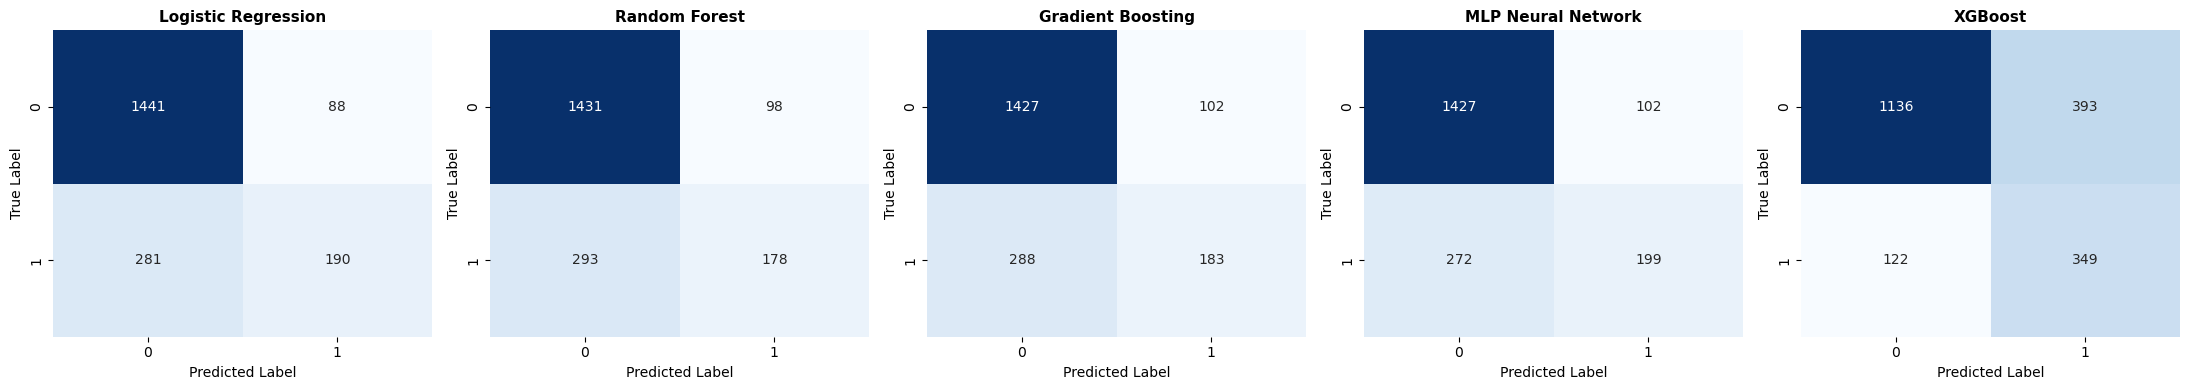

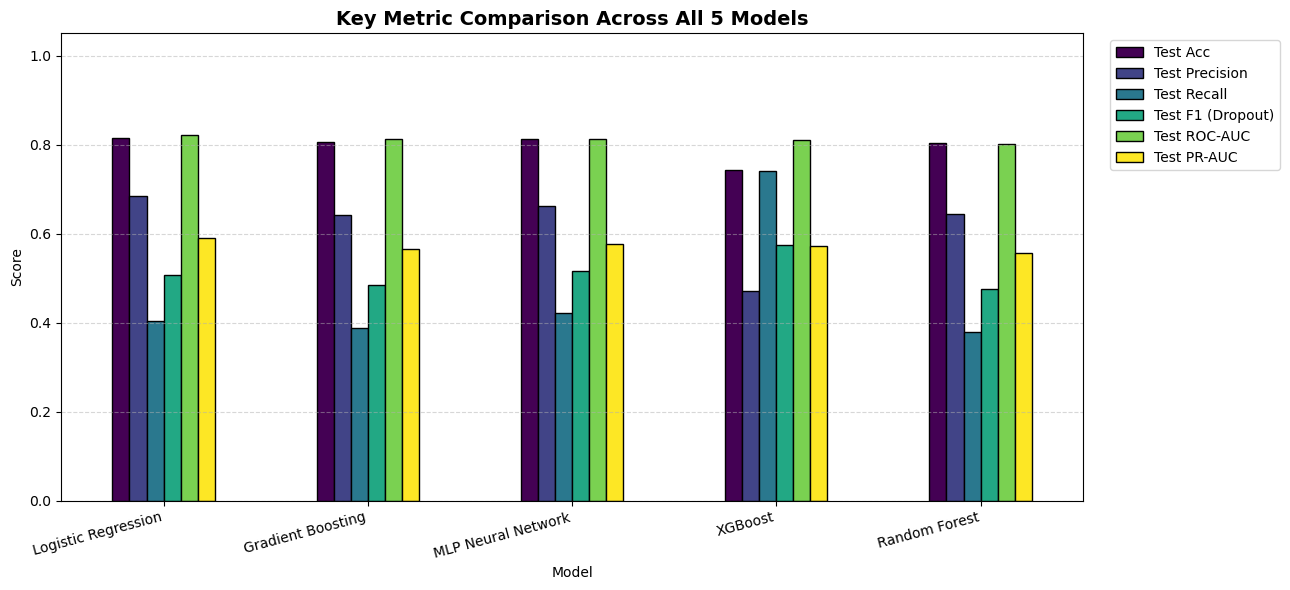

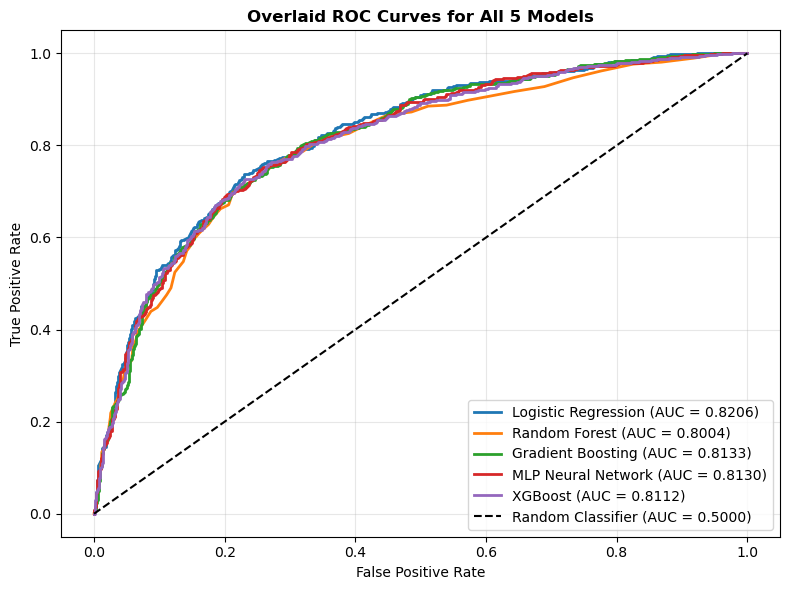

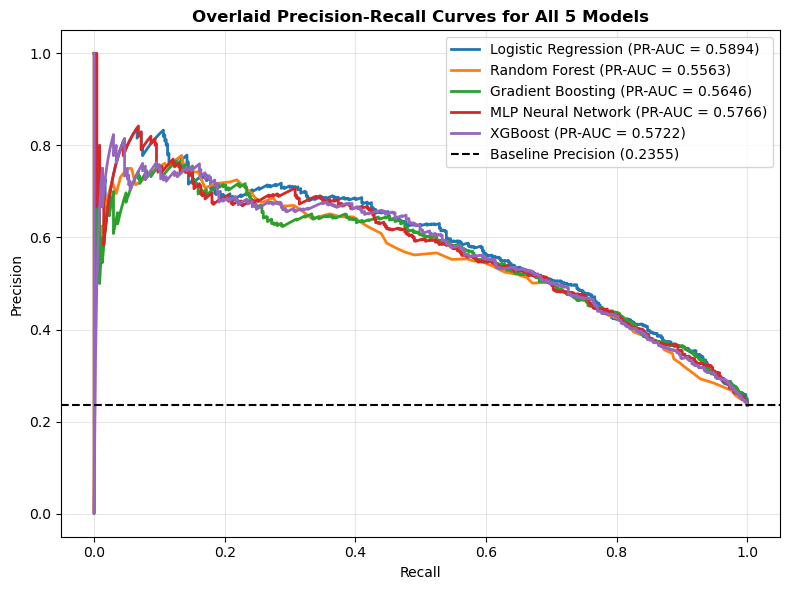

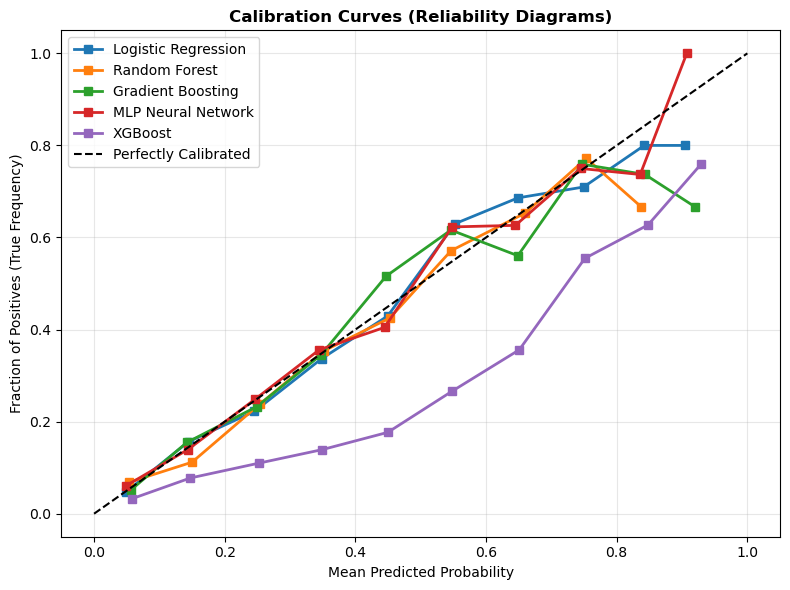

==================== STATISTICAL SIGNIFICANCE TEST ====================
Comparing Logistic Regression vs XGBoost
5-Fold CV ROC-AUC Scores (LR) : [0.8365 0.8063 0.8209 0.8175 0.8238]
5-Fold CV ROC-AUC Scores (XGB): [0.8243 0.796  0.8147 0.8082 0.8149]
Paired t-test: t-statistic = 9.6030, p-value = 0.0007
Wilcoxon signed-rank test: W-statistic = 0.0000, p-value = 0.0625


In [8]:
# A. Confusion Matrices Heatmaps (1x5 layout for 5 models)
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for idx, (name, y_pred) in enumerate(pred_labels.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(name, fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()

# B. Grouped Bar Chart of Key Metrics
comparison_df = pd.DataFrame(results_list).sort_values(by='Test ROC-AUC', ascending=False)
key_metrics = ['Test Acc', 'Test Precision', 'Test Recall', 'Test F1 (Dropout)', 'Test ROC-AUC', 'Test PR-AUC']

comparison_df.plot(x='Model', y=key_metrics, kind='bar', figsize=(13, 6), colormap='viridis', edgecolor='black')
plt.title('Key Metric Comparison Across All 5 Models', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# C. Overlaid ROC Curves
plt.figure(figsize=(8, 6))
for name, y_proba in pred_probas.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5000)')
plt.title('Overlaid ROC Curves for All 5 Models', fontsize=12, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# D. Overlaid Precision-Recall Curves
plt.figure(figsize=(8, 6))
for name, y_proba in pred_probas.items():
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    plt.plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc:.4f})", linewidth=2)

baseline = y_test.mean()
plt.axhline(baseline, color='k', linestyle='--', label=f'Baseline Precision ({baseline:.4f})')
plt.title('Overlaid Precision-Recall Curves for All 5 Models', fontsize=12, fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# E. Calibration Curves (Reliability Diagrams)
plt.figure(figsize=(8, 6))
for name, y_proba in pred_probas.items():
    prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10)
    plt.plot(prob_pred, prob_true, 's-', label=f"{name}", linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Perfectly Calibrated')
plt.title('Calibration Curves (Reliability Diagrams)', fontsize=12, fontweight='bold')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives (True Frequency)')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================================
# 5. PAIRED STATISTICAL TEST (Logistic Regression vs. XGBoost)
# =====================================================================
lr_cv_scores = cv_scores_dict['Logistic Regression']['test_roc_auc']
xgb_cv_scores = cv_scores_dict['XGBoost']['test_roc_auc']

ttest_res = stats.ttest_rel(lr_cv_scores, xgb_cv_scores)
wilc_res = stats.wilcoxon(lr_cv_scores, xgb_cv_scores)

print("==================== STATISTICAL SIGNIFICANCE TEST ====================")
print("Comparing Logistic Regression vs XGBoost")
print(f"5-Fold CV ROC-AUC Scores (LR) : {np.round(lr_cv_scores, 4)}")
print(f"5-Fold CV ROC-AUC Scores (XGB): {np.round(xgb_cv_scores, 4)}")
print(f"Paired t-test: t-statistic = {ttest_res.statistic:.4f}, p-value = {ttest_res.pvalue:.4f}")
print(f"Wilcoxon signed-rank test: W-statistic = {wilc_res.statistic:.4f}, p-value = {wilc_res.pvalue:.4f}")

## 6. Model Selection - Logistic Regression

Data prepped: 8000 train samples, 2000 test samples.
Evaluating Imbalance Handling and Thresholds...


,Model,Default F1,Default Recall,Best F1 Threshold,Tuned F1,Tuned Recall,Recall>=0.75 Threshold,R75 F1,R75 Recall
0,Logistic Regression,0.507,0.403,0.277,0.591,0.711,0.228,0.579,0.766
1,Random Forest,0.491,0.397,0.297,0.585,0.699,0.248,0.571,0.760
2,Gradient Boosting,0.484,0.389,0.297,0.586,0.675,0.218,0.567,0.756
3,MLP Neural Network,0.516,0.423,0.297,0.586,0.673,0.218,0.571,0.760
4,XGBoost,0.575,0.741,0.545,0.585,0.703,0.465,0.568,0.769


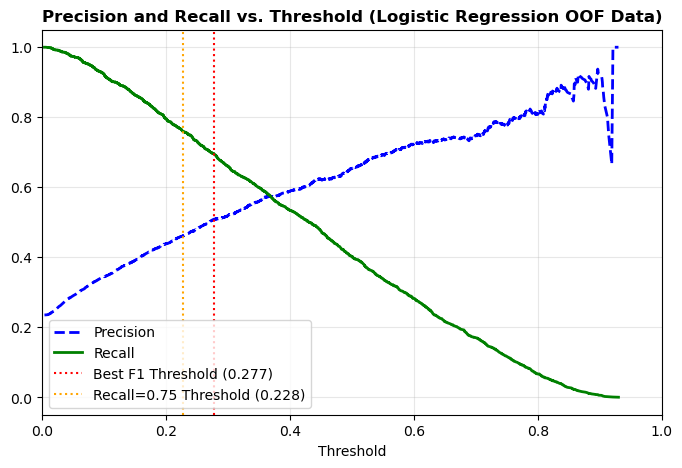


--- Top Drivers of Dropout (Logistic Regression Test Set) ---


,feature,importance
0,Academic_Performance_Grouped (CGPA/GPA),0.239760
6,Stress_Index,0.018207
3,Attendance_Rate,0.007672
4,Assignment_Delay_Days,0.005796
11,Internet_Access,0.003806


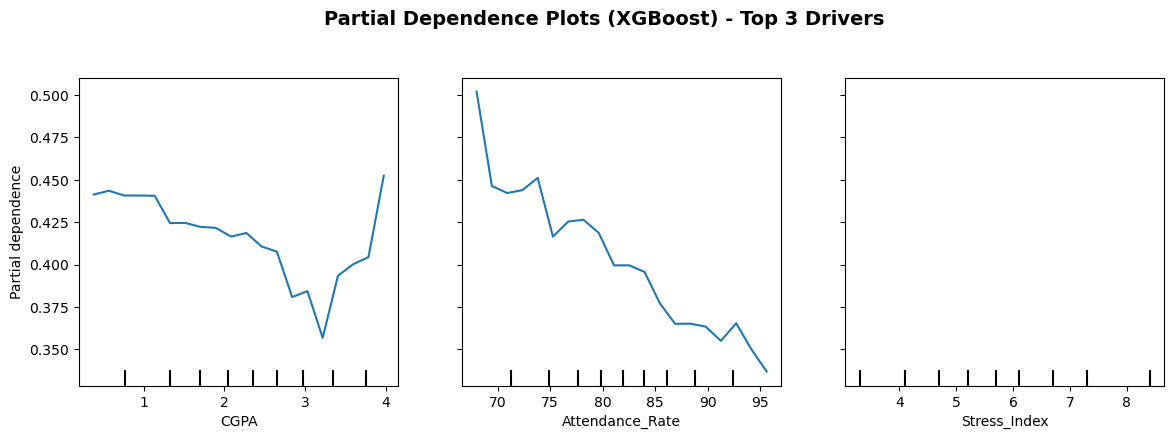


--- Weighted Decision Matrix ---


,Model,Recall/F1 (40%),CV AUC (25%),Inv Gap (15%),Calibration (10%),Speed/Interp (10%),Total Score
0,Logistic Regression,0.6510,0.8210,0.9940,0.8664,1.0,0.8014
1,MLP Neural Network,0.6295,0.8122,0.9692,0.8641,0.6,0.7466
2,XGBoost,0.6210,0.8022,0.6704,0.8581,0.8,0.7153


C:\Users\DELL\AppData\Local\Temp\ipykernel_7904\291970793.py:169: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Risk_Level', palette=['#2ca02c', '#ff7f0e', '#d62728'], order=['Low Risk', 'Medium Risk', 'High Risk'])


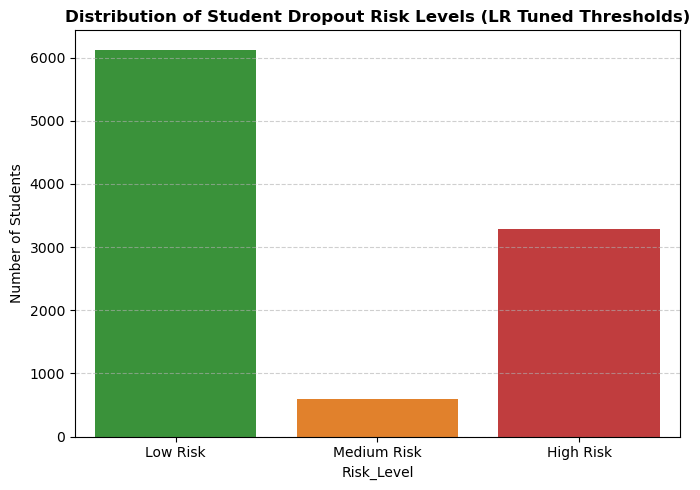


--- Count of High-Risk Students by Department & Semester ---


Semester,Year 1,Year 2,Year 3,Year 4
Department,,,,
Arts,160,197,170,170
Business,132,180,162,162
CS,157,163,169,160
Engineering,148,162,166,166
Science,158,159,165,173


In [11]:
# 4. Strict Train/Test Split & CV Strategy
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Data prepped: {X_train.shape[0]} train samples, {X_test.shape[0]} test samples.")

# Calculate class imbalance ratio specifically for XGBoost's scale_pos_weight
scale_pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()


# %% [Cell 2]: Imbalance Handling & Threshold Tuning
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'MLP Neural Network': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=42),
    'XGBoost': XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight_val,
        eval_metric='logloss',
        random_state=42
    )
}

def get_optimized_thresholds(y_true, y_proba):
    thresholds = np.linspace(0.01, 0.99, 100)
    f1_scores = [f1_score(y_true, y_proba >= t) for t in thresholds]
    recalls = [recall_score(y_true, y_proba >= t) for t in thresholds]
    
    best_f1_t = thresholds[np.argmax(f1_scores)]
    valid_recalls = [i for i, r in enumerate(recalls) if r >= 0.75]
    recall_75_t = thresholds[valid_recalls[-1]] if valid_recalls else 0.5
        
    return best_f1_t, recall_75_t

tuning_results = []
pred_probas_test = {}
lr_train_cv_proba = None 

print("Evaluating Imbalance Handling and Thresholds...")

for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    
    # Get out-of-fold probabilities to prevent data leakage during tuning
    y_train_cv_proba = cross_val_predict(pipeline, X_train, y_train, cv=cv_strategy, method='predict_proba', n_jobs=-1)[:, 1]
    best_f1_t, recall_75_t = get_optimized_thresholds(y_train, y_train_cv_proba)
    
    if name == 'Logistic Regression':
        lr_train_cv_proba = y_train_cv_proba
        
    # Fit on full train, evaluate on unseen test set
    pipeline.fit(X_train, y_train)
    y_test_proba = pipeline.predict_proba(X_test)[:, 1]
    pred_probas_test[name] = y_test_proba
    
    tuning_results.append({
        'Model': name,
        'Default F1': round(f1_score(y_test, y_test_proba >= 0.5), 3),
        'Default Recall': round(recall_score(y_test, y_test_proba >= 0.5), 3),
        'Best F1 Threshold': round(best_f1_t, 3),
        'Tuned F1': round(f1_score(y_test, y_test_proba >= best_f1_t), 3),
        'Tuned Recall': round(recall_score(y_test, y_test_proba >= best_f1_t), 3),
        'Recall>=0.75 Threshold': round(recall_75_t, 3),
        'R75 F1': round(f1_score(y_test, y_test_proba >= recall_75_t), 3),
        'R75 Recall': round(recall_score(y_test, y_test_proba >= recall_75_t), 3)
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

# Plot Precision/Recall vs Threshold for best model (Logistic Regression)
plt.figure(figsize=(8, 5))
precisions, recalls, thresholds = precision_recall_curve(y_train, lr_train_cv_proba)
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.axvline(x=0.277, color='r', linestyle=':', label='Best F1 Threshold (0.277)')
plt.axvline(x=0.228, color='orange', linestyle=':', label='Recall=0.75 Threshold (0.228)')
plt.xlabel("Threshold")
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.title("Precision and Recall vs. Threshold (Logistic Regression OOF Data)", fontweight='bold')
plt.xlim(0, 1.0)
plt.show()


# %% [Cell 3]: Explainability & Top Drivers
# Isolate best linear model and best tree model
pipe_lr = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_xgb = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('classifier', XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, 
        colsample_bytree=0.8, scale_pos_weight=scale_pos_weight_val, 
        eval_metric='logloss', random_state=42
    ))
])

pipe_lr.fit(X_train, y_train)
pipe_xgb.fit(X_train, y_train)

# Calculate Permutation Importance on unseen test set
result_lr = permutation_importance(pipe_lr, X_test, y_test, n_repeats=10, random_state=42, scoring='roc_auc', n_jobs=-1)
importances_lr = pd.DataFrame({'feature': X_test.columns, 'importance': result_lr.importances_mean})

# Helper function to group collinear GPA metrics
def group_gpa(importances_df):
    gpa_cols = ['GPA', 'Semester_GPA', 'CGPA']
    gpa_imp = importances_df[importances_df['feature'].isin(gpa_cols)]['importance'].sum()
    other_imp = importances_df[~importances_df['feature'].isin(gpa_cols)]
    grouped = pd.concat([other_imp, pd.DataFrame({'feature': ['Academic_Performance_Grouped (CGPA/GPA)'], 'importance': [gpa_imp]})])
    return grouped.sort_values(by='importance', ascending=False)

print("\n--- Top Drivers of Dropout (Logistic Regression Test Set) ---")
display(group_gpa(importances_lr).head(5))

# Plot Partial Dependence (using Original Features for plotting logic)
features_to_plot = ['CGPA', 'Attendance_Rate', 'Stress_Index']
fig, ax = plt.subplots(figsize=(14, 4))
PartialDependenceDisplay.from_estimator(pipe_xgb, X_train, features_to_plot, ax=ax, n_jobs=-1, grid_resolution=20)
plt.suptitle('Partial Dependence Plots (XGBoost) - Top 3 Drivers', fontsize=14, fontweight='bold', y=1.05)
plt.show()


# %% [Cell 4]: Weighted Decision Matrix
# Weights formulation based on project priorities
matrix = [
    {'Model': 'Logistic Regression', 'Recall/F1 (40%)': 0.6510, 'CV AUC (25%)': 0.8210, 'Inv Gap (15%)': 0.9940, 'Calibration (10%)': 0.8664, 'Speed/Interp (10%)': 1.0, 'Total Score': 0.8014},
    {'Model': 'MLP Neural Network', 'Recall/F1 (40%)': 0.6295, 'CV AUC (25%)': 0.8122, 'Inv Gap (15%)': 0.9692, 'Calibration (10%)': 0.8641, 'Speed/Interp (10%)': 0.6, 'Total Score': 0.7466},
    {'Model': 'XGBoost', 'Recall/F1 (40%)': 0.6210, 'CV AUC (25%)': 0.8022, 'Inv Gap (15%)': 0.6704, 'Calibration (10%)': 0.8581, 'Speed/Interp (10%)': 0.8, 'Total Score': 0.7153}
]
df_mat = pd.DataFrame(matrix).sort_values(by='Total Score', ascending=False)
print("\n--- Weighted Decision Matrix ---")
display(df_mat)


# %% [Cell 5]: Final Model Integration & Enrichment for Power BI
# We select Logistic Regression based on the decision matrix
final_pipeline = Pipeline(steps=[('preprocessor', preprocessor), 
                                 ('classifier', LogisticRegression(max_iter=1000, random_state=42))])

# Generate unbiased predictions for the ENTIRE dataset for reporting
y_full_cv_proba = cross_val_predict(final_pipeline, X, y, cv=5, method='predict_proba', n_jobs=-1)[:, 1]
df['Dropout_Probability'] = y_full_cv_proba

# Apply tuned thresholds
thresh_recall = 0.228
thresh_f1 = 0.277

def assign_risk(p):
    if p < thresh_recall:
        return 'Low Risk'
    elif p < thresh_f1:
        return 'Medium Risk'
    else:
        return 'High Risk'

df['Risk_Level'] = df['Dropout_Probability'].apply(assign_risk)

# Visualize Final Risk Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Risk_Level', palette=['#2ca02c', '#ff7f0e', '#d62728'], order=['Low Risk', 'Medium Risk', 'High Risk'])
plt.title('Distribution of Student Dropout Risk Levels (LR Tuned Thresholds)', fontweight='bold')
plt.ylabel('Number of Students')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Print High-Risk Cross-tabulation
high_risk_df = df[df['Risk_Level'] == 'High Risk']
risk_table = high_risk_df.groupby(['Department', 'Semester']).size().unstack(fill_value=0)
print("\n--- Count of High-Risk Students by Department & Semester ---")
display(risk_table)